THÔNG TIN DỮ LIỆU ĐỒ ÁN
- Nguồn Benchmark: PassMark CPU Benchmarks (Kaggle)
- Ngày thu thập (chạy notebook): 11/11/2026

Số lượng CPU hợp lệ (Đơn nhân, có điểm Benchmark): 3785 dòng.


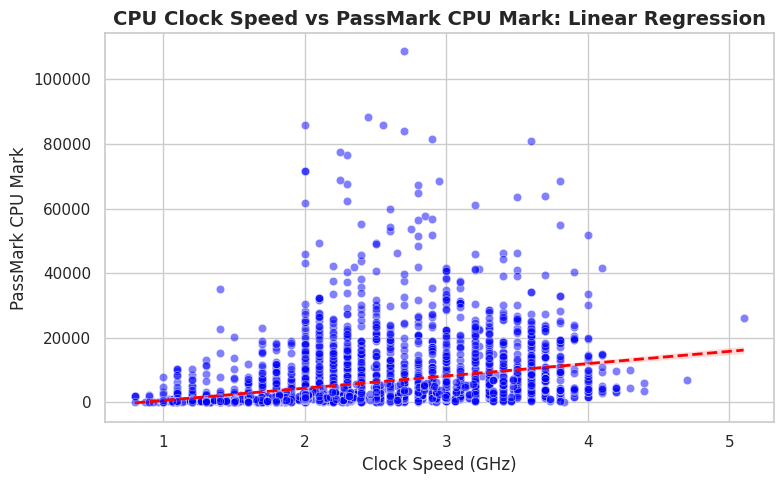

In [24]:
# ==============================================================================
# PHẦN 1 (KIÊN): TIỀN XỬ LÝ, LỌC CPUCOUNT == 1 & CHIA TRAIN/TEST
# ==============================================================================
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split

sns.set_theme(style="whitegrid")

print("==================================================")
print("THÔNG TIN DỮ LIỆU ĐỒ ÁN")
print("- Nguồn Benchmark: PassMark CPU Benchmarks (Kaggle)")
print("- Ngày thu thập (chạy notebook): 11/11/2026")
print("==================================================\n")

# 1. Nạp dữ liệu
df_main = pd.read_csv('Final_CPU_Data_Cleaned.csv')
df_bench = pd.read_csv('CPU_benchmark_v4.csv')

# 2. Xử lý trùng lặp theo đúng yêu cầu: Lọc rõ ràng cpuCount == 1
if 'cpuCount' in df_main.columns:
    df_main = df_main[df_main['cpuCount'] == 1]

# Loại bỏ các dòng bị lặp tên (nếu vẫn còn)
df_main = df_main.drop_duplicates(subset=['name'])
df_bench = df_bench.drop_duplicates(subset=['cpuName'])

# 3. Merge dữ liệu
df_merged = pd.merge(df_main, df_bench[['cpuName', 'cpuMark']], 
                     left_on='name', right_on='cpuName', how='inner')

target_col = 'cpuMark' 

# 4. Làm sạch dữ liệu và xuất file
df_clean = df_merged.dropna(subset=['speed_ghz', target_col]).copy()
df_clean = df_clean[(df_clean['speed_ghz'] > 0) & (df_clean[target_col] > 0)]

df_clean.to_csv('Merged_CPU_Data_With_Score.csv', index=False)
print(f"Số lượng CPU hợp lệ (Đơn nhân, có điểm Benchmark): {len(df_clean)} dòng.")

# 5. Trực quan hóa EDA
plt.figure(figsize=(8, 5))
sns.regplot(x=df_clean['speed_ghz'], y=df_clean[target_col], 
            scatter_kws={'alpha':0.5, 'color':'blue', 'edgecolor': 'w', 'linewidths': 0.5}, 
            line_kws={'color':'red', 'linewidth': 2, 'linestyle': '--'})
plt.title('CPU Clock Speed vs PassMark CPU Mark: Linear Regression', fontsize=14, fontweight='bold')
plt.xlabel('Clock Speed (GHz)')
plt.ylabel('PassMark CPU Mark')
plt.tight_layout()
plt.show()

# 6. Tách biến và Chia Train/Test
X_raw = df_clean[['speed_ghz']].values
y_vec = df_clean[[target_col]].values.reshape(-1, 1)

X_train_raw, X_test_raw, y_train, y_test = train_test_split(X_raw, y_vec, test_size=0.2, random_state=42)

# 7. Chuẩn hóa Z-score (Chỉ fit trên Train)
X_mean = np.mean(X_train_raw)
X_std = np.std(X_train_raw)

X_train_scaled = (X_train_raw - X_mean) / X_std
X_test_scaled = (X_test_raw - X_mean) / X_std

# 8. Thêm cột bias
X_train_b = np.c_[np.ones((len(X_train_scaled), 1)), X_train_scaled]
X_test_b = np.c_[np.ones((len(X_test_scaled), 1)), X_test_scaled]

In [22]:
# ==============================================================================
# PHẦN 2 (XUÂN HẠ): THUẬT TOÁN (Tối ưu hóa hàm Cost và Normal Equation)
# ==============================================================================

# Hàm Cost Function đã loại bỏ phụ thuộc biến m toàn cục
def compute_cost(X, y, theta):
    m_local = len(y)
    predictions = X.dot(theta)
    errors = predictions - y
    return (1 / (2 * m_local)) * np.sum(np.square(errors))

# Gradient Descent huấn luyện trên tập Train
def gradient_descent(X, y, theta, learning_rate, iterations):
    m_local = len(y)
    cost_history = np.zeros(iterations + 1)
    theta_history = []
    
    cost_history[0] = compute_cost(X, y, theta)
    theta_history.append(theta.copy())
    
    for i in range(iterations):
        predictions = X.dot(theta)
        gradients = (1 / m_local) * X.T.dot(predictions - y)
        theta = theta - learning_rate * gradients
        
        cost_history[i + 1] = compute_cost(X, y, theta)
        theta_history.append(theta.copy())
        
    return theta, cost_history, theta_history

alpha = 0.1
iterations = 500
theta_initial = np.zeros((2, 1))

# Chạy GD trên tập huấn luyện (Train)
theta_gd, cost_history, theta_history = gradient_descent(X_train_b, y_train, theta_initial, alpha, iterations)

# Hàm Normal Equation sử dụng giả nghịch đảo (pinv) để tránh lỗi ma trận suy biến
def normal_equation(X, y):
    return np.linalg.pinv(X.T.dot(X)).dot(X.T).dot(y)

theta_analytic = normal_equation(X_train_b, y_train)

print("\n--- KẾT QUẢ HUẤN LUYỆN TRÊN TẬP TRAIN ---")
print(f"Hệ số chặn (theta_0): {theta_gd[0][0]:.4f}")
print(f"Hệ số góc (theta_1):  {theta_gd[1][0]:.4f}")
sai_so = np.sum(np.abs(theta_gd - theta_analytic))
print(f"=> Độ chênh lệch giữa GD và Giải tích: {sai_so:.8f}")


--- KẾT QUẢ HUẤN LUYỆN TRÊN TẬP TRAIN ---
Hệ số chặn (theta_0): 6051.4336
Hệ số góc (theta_1):  2776.7472
=> Độ chênh lệch giữa GD và Giải tích: 0.00000000



--- ĐÁNH GIÁ MÔ HÌNH TRÊN TẬP TEST KHÁCH QUAN ---
Pearson Correlation (r): 0.2865
R^2 Score (Test):        0.0790
MSE (Test):              85185927.0719
RMSE (Test):             9229.6223


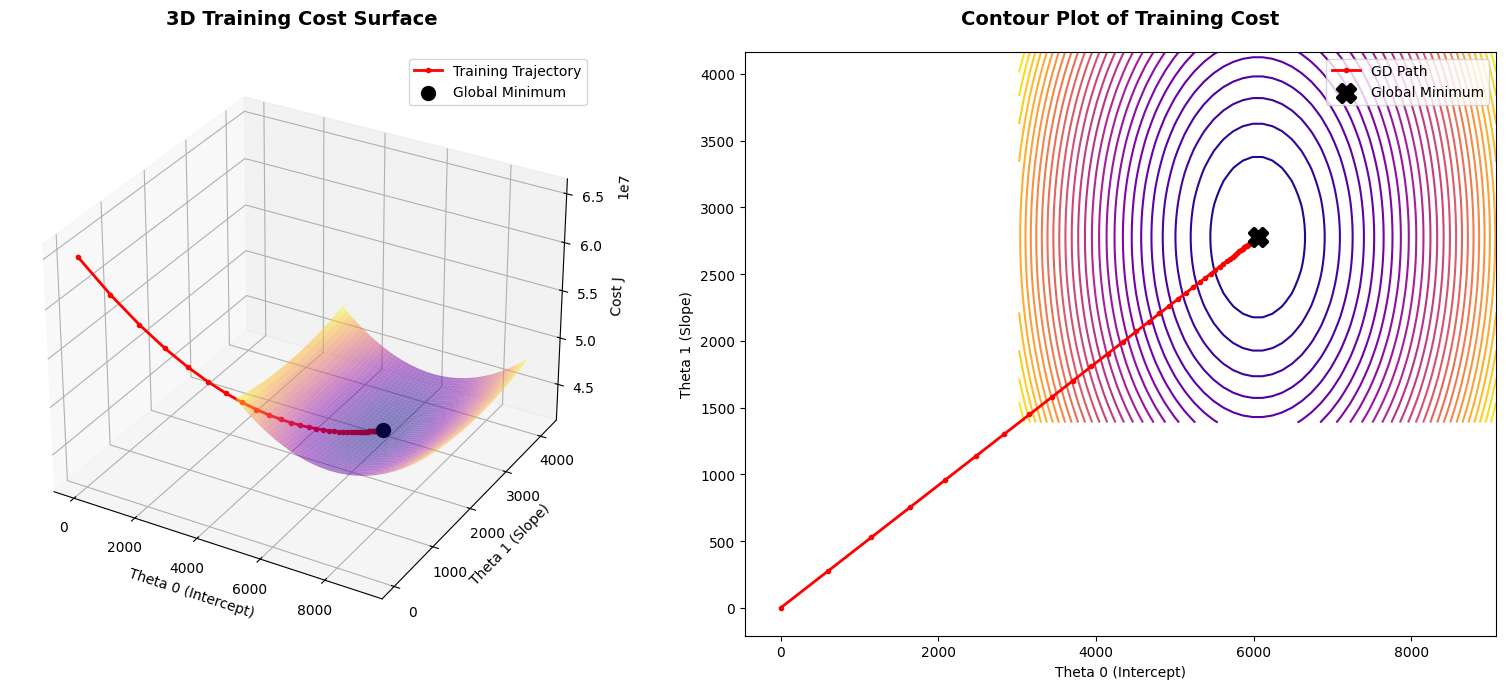

In [ ]:
# ==============================================================================
# PHẦN 3 (ĐẠT SANG): ĐÁNH GIÁ TRÊN TẬP TEST & TRỰC QUAN HÓA 3D
# ==============================================================================
from mpl_toolkits.mplot3d import Axes3D

# 1. Tính toán hệ số tương quan Pearson (trên toàn bộ dataset)
r_matrix = np.corrcoef(X_raw.flatten(), y_vec.flatten())
pearson_r = r_matrix[0, 1]

# 2. Đánh giá mô hình trên tập TEST chưa từng thấy
y_test_pred = X_test_b.dot(theta_gd)

mse_test = np.mean(np.square(y_test_pred - y_test))
rmse_test = np.sqrt(mse_test)

ss_total_test = np.sum(np.square(y_test - np.mean(y_test)))
ss_res_test = np.sum(np.square(y_test - y_test_pred))
r2_test = 1 - (ss_res_test / ss_total_test)

print("\n--- ĐÁNH GIÁ MÔ HÌNH TRÊN TẬP TEST KHÁCH QUAN ---")
print(f"Pearson Correlation (r): {pearson_r:.4f}")
print(f"R^2 Score (Test):        {r2_test:.4f}")
print(f"MSE (Test):              {mse_test:.4f}")
print(f"RMSE (Test):             {rmse_test:.4f}")

# (Code phần đánh giá R2, MSE ở trên giữ nguyên)

# 3. Vẽ 3D Cost Surface & Contour Plot thể hiện ĐẦY ĐỦ quỹ đạo
theta0_hist = [t[0][0] for t in theta_history]
theta1_hist = [t[1][0] for t in theta_history]

# Tính giới hạn bao trọn toàn bộ quỹ đạo lịch sử GD + 20% padding
t0_min, t0_max = min(theta0_hist), max(theta0_hist)
t1_min, t1_max = min(theta1_hist), max(theta1_hist)

pad0 = (t0_max - t0_min) * 0.2 if t0_max != t0_min else 2000
pad1 = (t1_max - t1_min) * 0.2 if t1_max != t1_min else 2000

theta0_range = np.linspace(t0_min - pad0, t0_max + pad0, 50)
theta1_range = np.linspace(t1_min - pad1, t1_max + pad1, 50)

T0, T1 = np.meshgrid(theta0_range, theta1_range)
J_vals = np.zeros((len(theta0_range), len(theta1_range)))

for i in range(len(theta0_range)):
    for j in range(len(theta1_range)):
        t = np.array([[theta0_range[i]], [theta1_range[j]]])
        J_vals[i, j] = compute_cost(X_train_b, y_train, t)

J_vals = J_vals.T

fig = plt.figure(figsize=(16, 7))
plt.style.use('default') 

ax1 = fig.add_subplot(121, projection='3d')
ax1.plot_surface(T0, T1, J_vals, cmap='plasma', alpha=0.5, edgecolor='none')
ax1.plot(theta0_hist, theta1_hist, cost_history, color='red', linewidth=2, marker='o', markersize=3, label='Training Trajectory')
ax1.scatter(theta_gd[0][0], theta_gd[1][0], cost_history[-1], color='black', s=100, zorder=5, label='Global Minimum')
ax1.set_title('3D Training Cost Surface', fontsize=14, fontweight='bold', pad=20)
ax1.set_xlabel('Theta 0 (Intercept)')
ax1.set_ylabel('Theta 1 (Slope)')
ax1.set_zlabel('Cost J')
ax1.legend()

ax2 = fig.add_subplot(122)
levels = np.logspace(np.log10(np.min(J_vals)), np.log10(np.max(J_vals)), 30)
ax2.contour(T0, T1, J_vals, levels=levels, cmap='plasma')
ax2.plot(theta0_hist, theta1_hist, color='red', linewidth=2, marker='o', markersize=3, label='GD Path')
ax2.scatter(theta_gd[0][0], theta_gd[1][0], color='black', marker='X', s=150, linewidths=3, label='Global Minimum', zorder=5)
ax2.set_title('Contour Plot of Training Cost', fontsize=14, fontweight='bold', pad=20)
ax2.set_xlabel('Theta 0 (Intercept)')
ax2.set_ylabel('Theta 1 (Slope)')
ax2.legend()

plt.tight_layout()
plt.show()